# Análise de Óbitos por Local de Ocorrência
## Sprint 1 - PyAnalytics

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [37]:
df = pd.read_csv("/content/sim_sc_processado_analitico.csv")

df.head()

/tmp/ipykernel_875/3888458797.py:1: DtypeWarning: Columns (2,6,9,11,18,19,26,37,38,39,40,41) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/sim_sc_processado_analitico.csv")


,CONTADOR,TIPOBITO,DTOBITO,HORAOBITO,NATURAL,CODMUNNATU,DTNASC,IDADE,SEXO,RACACOR,...,RACACOR_COD,LOCOCOR_COD,IDADE_COD,IDADE_ANOS,ANO_OBITO,ANO_NASC,DATA_OBITO_VALIDA,DATA_NASC_VALIDA,SC_RESIDENCIA,SC_OCORRENCIA
0,2527,2,2000-12-12,NaN,800.0,NaN,1933-11-01,467.0,Masculino,Preta,...,2.0,3.0,467.0,67.0,2000.0,1933.0,True,True,False,True
1,14333,2,2000-11-19,NaN,850.0,NaN,1978-10-20,422.0,Masculino,Branca,...,1.0,5.0,422.0,22.0,2000.0,1978.0,True,True,False,True
2,14334,2,2000-10-16,NaN,842.0,NaN,1910-05-31,490.0,Masculino,Branca,...,1.0,1.0,490.0,90.0,2000.0,1910.0,True,True,False,True
3,51178,2,2000-07-05,NaN,NaN,NaN,1949-12-10,450.0,Masculino,Parda,...,4.0,9.0,450.0,50.0,2000.0,1949.0,True,True,False,True
4,109,2,2000-02-02,NaN,800.0,NaN,1979-05-07,420.0,Masculino,Branca,...,1.0,5.0,420.0,20.0,2000.0,1979.0,True,True,False,True


## 1. Preparação dos Dados

In [38]:
print(df.columns.tolist())
df.info()

['CONTADOR', 'TIPOBITO', 'DTOBITO', 'HORAOBITO', 'NATURAL', 'CODMUNNATU', 'DTNASC', 'IDADE', 'SEXO', 'RACACOR', 'ESTCIV', 'ESC', 'ESC2010', 'SERIESCFAL', 'OCUP', 'CODMUNRES', 'LOCOCOR', 'CODMUNOCOR', 'IDADEMAE', 'ESCMAE', 'ESCMAE2010', 'SERIESCMAE', 'OCUPMAE', 'QTDFILVIVO', 'QTDFILMORT', 'GRAVIDEZ', 'GESTACAO', 'PARTO', 'OBITOPARTO', 'PESO', 'OBITOGRAV', 'OBITOPUERP', 'ASSISTMED', 'EXAME', 'CIRURGIA', 'NECROPSIA', 'CAUSABAS', 'LINHAA', 'LINHAB', 'LINHAC', 'LINHAD', 'LINHAII', 'CIRCOBITO', 'ACIDTRAB', 'FONTE', 'DTOBITO_BRUTO', 'DTNASC_BRUTO', 'SEXO_COD', 'RACACOR_COD', 'LOCOCOR_COD', 'IDADE_COD', 'IDADE_ANOS', 'ANO_OBITO', 'ANO_NASC', 'DATA_OBITO_VALIDA', 'DATA_NASC_VALIDA', 'SC_RESIDENCIA', 'SC_OCORRENCIA']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1502195 entries, 0 to 1502194
Data columns (total 58 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   CONTADOR           1502195 non-null  int64  
 1   TIPOBITO       

In [39]:
# Verifica valores nulos nas colunas que vamos usar
colunas_interesse = ["LOCOCOR", "IDADE", "ASSISTMED", "CAUSABAS", "CODMUNOCOR"]
df[colunas_interesse].isnull().sum()

,0
LOCOCOR,2108
IDADE,172
ASSISTMED,262839
CAUSABAS,0
CODMUNOCOR,0


In [40]:
# Exemplos de linhas nulas em LOCOCOR
print("LOCOCOR nulos")
df[df["LOCOCOR"].isna()][["CONTADOR", "LOCOCOR", "IDADE", "ASSISTMED", "CAUSABAS", "CODMUNOCOR"]].head(10)

LOCOCOR nulos


,CONTADOR,LOCOCOR,IDADE,ASSISTMED,CAUSABAS,CODMUNOCOR
1288094,111,NaN,419.0,2.0,8147,4207304
1289231,996,NaN,454.0,2.0,9289,4216602
1289313,1078,NaN,480.0,2.0,7989,4205407
1289318,1083,NaN,460.0,2.0,7989,4200606
1289341,1106,NaN,456.0,1.0,2503,4205407
1289342,1107,NaN,454.0,1.0,8199,4200903
1289400,1165,NaN,428.0,1.0,8199,4205407
1289492,1257,NaN,464.0,1.0,486X,4202909
1289494,1259,NaN,491.0,NaN,797X,4202909
1289798,1563,NaN,462.0,NaN,436X,4216305


In [41]:
# Exemplos de linhas nulas em IDADE
print("IDADE nulos")
df[df["IDADE"].isna()][["CONTADOR", "LOCOCOR", "IDADE", "ASSISTMED", "CAUSABAS", "CODMUNOCOR"]].head(10)

IDADE nulos


,CONTADOR,LOCOCOR,IDADE,ASSISTMED,CAUSABAS,CODMUNOCOR
182746,4166,Hospital,NaN,NaN,P021,420320
188961,10381,Hospital,NaN,NaN,P022,420330
189789,11209,Outros,NaN,NaN,Y098,421580
200900,22320,Hospital,NaN,1.0,P025,421175
1390424,191,Hospital,NaN,1.0,C719,4106902
1390604,371,Outros,NaN,2.0,V892,4106902
1390618,385,NaN,NaN,1.0,K746,4106902
1391487,1254,Via publica,NaN,1.0,V892,4205704
1392249,2016,NaN,NaN,9.0,I219,4207908
1393447,3214,NaN,NaN,1.0,J988,4209003


In [42]:
# Exemplos de linhas nulas em ASSISTMED
print("ASSISTMED nulos")
df[df["ASSISTMED"].isna()][["CONTADOR", "LOCOCOR", "IDADE", "ASSISTMED", "CAUSABAS", "CODMUNOCOR"]].head(10)

ASSISTMED nulos


,CONTADOR,LOCOCOR,IDADE,ASSISTMED,CAUSABAS,CODMUNOCOR
0,2527,Domicilio,467.0,NaN,J449,4216909
1,14333,Outros,422.0,NaN,W698,4211405
2,14334,Hospital,490.0,NaN,J439,4203303
3,51178,Ignorado,450.0,NaN,C786,4207684
4,109,Outros,420.0,NaN,W698,4211900
5,147,Via publica,440.0,NaN,I255,4201950
6,95695,Outros,418.0,NaN,W698,4202107
7,249,Hospital,102.0,NaN,P392,4209102
10,6259,Domicilio,457.0,NaN,C64,4219101
11,51872,Outros,438.0,NaN,X938,4208203


In [43]:
# Verifica duplicatas
duplicatas = df.duplicated()
print(f"Total de linhas duplicadas: {duplicatas.sum()}")
df[duplicatas].head(10)

Total de linhas duplicadas: 0


,CONTADOR,TIPOBITO,DTOBITO,HORAOBITO,NATURAL,CODMUNNATU,DTNASC,IDADE,SEXO,RACACOR,...,RACACOR_COD,LOCOCOR_COD,IDADE_COD,IDADE_ANOS,ANO_OBITO,ANO_NASC,DATA_OBITO_VALIDA,DATA_NASC_VALIDA,SC_RESIDENCIA,SC_OCORRENCIA


## Observações sobre a Preparação dos Dados

Durante a preparação dos dados, foram identificados valores ausentes nas seguintes colunas de interesse:

- **LOCOCOR** (local de óbito): 13 registros sem informação no recorte de Araranguá.
Esses registros foram removidos via dropna, pois o local de óbito é a variável
central de toda a análise — sem ela, o registro não contribui para nenhum dos gráficos.
A perda representa menos de 0,2% dos dados, sendo desprezível.

- **IDADE**: poucos registros sem informação. Mantidos no dataset — a ausência é
legítima e não compromete os gráficos, que usam a coluna IDADE_ANOS (derivada pelo
pipeline). Registros sem idade simplesmente não aparecem no boxplot.

- **ASSISTMED** (assistência médica): coluna com expressivo número de ausências no
dataset geral de SC. Segundo o README do projeto, nem toda coluna da API vem preenchida
em todos os registros, e valores vazios são normalizados como NaN pelo pipeline.
Esses registros foram mantidos e classificados como "Não informado" nos gráficos,
sem imputação de valores, para não distorcer a análise.

Não foram encontradas linhas duplicadas no dataset.

# **Filtro para Araranguá**

In [44]:
CODIGO_ARARANGUA = 4201406

df_limpo = df[df["CODMUNOCOR"] == CODIGO_ARARANGUA].dropna(subset=["LOCOCOR"]).copy()

#mapeia ASSISTMED para texto legível
mapa_assistmed = {1.0: "Sim", 2.0: "Não", 9.0: "Ignorado"}
df_limpo["ASSISTMED_LABEL"] = df_limpo["ASSISTMED"].map(mapa_assistmed).fillna("Não informado")

print(f"Total de óbitos em Araranguá: {len(df_limpo)}")

Total de óbitos em Araranguá: 6896


In [45]:
print(f"Antes do dropna: {len(df[df['CODMUNOCOR'] == CODIGO_ARARANGUA])}")
print(f"Depois do dropna: {len(df_limpo)}")
print(f"Removidos: {len(df[df['CODMUNOCOR'] == CODIGO_ARARANGUA]) - len(df_limpo)}")

Antes do dropna: 6909
Depois do dropna: 6896
Removidos: 13


## 2. Análise Comparativa de Proporção (Local x Idade)

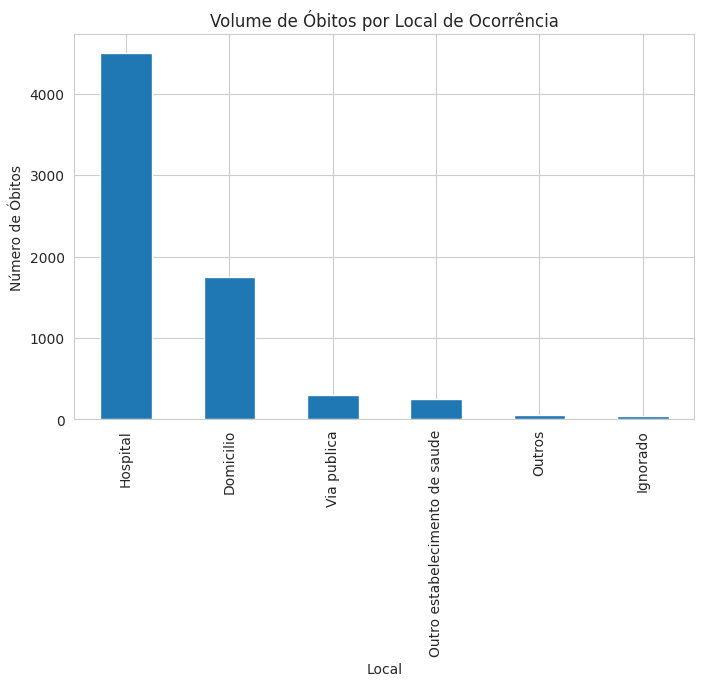

In [46]:
# Proporção de óbitos por local de ocorrência
contagem_local = df_limpo["LOCOCOR"].value_counts()

plt.figure(figsize=(8,5))
contagem_local.plot(kind="bar")
plt.title("Volume de Óbitos por Local de Ocorrência")
plt.xlabel("Local")
plt.ylabel("Número de Óbitos")
plt.show()

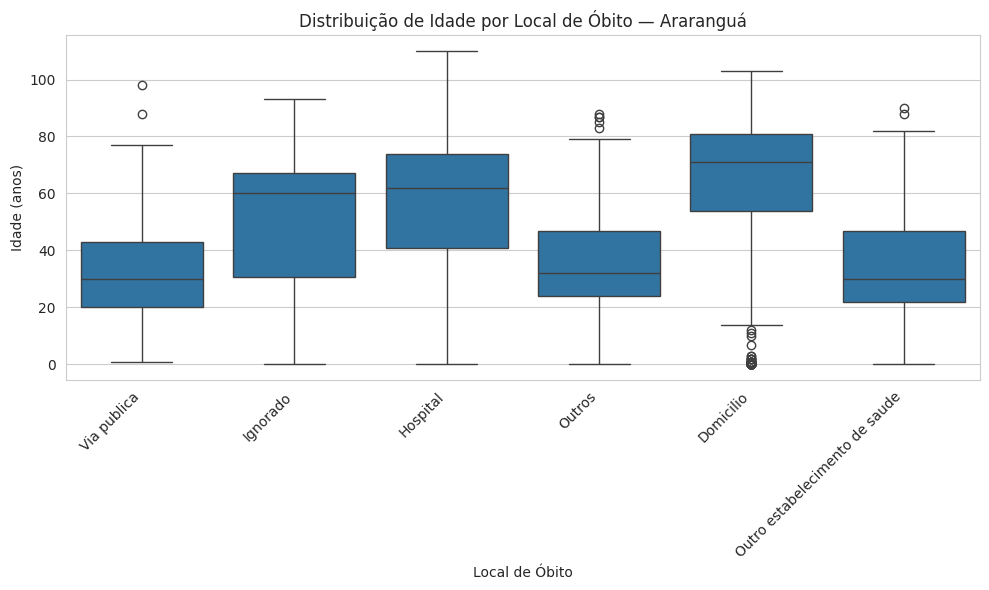

In [47]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df_limpo, x="LOCOCOR", y="IDADE_ANOS")
plt.title("Distribuição de Idade por Local de Óbito — Araranguá")
plt.xlabel("Local de Óbito")
plt.ylabel("Idade (anos)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 3. Indicador de Amparo Médico

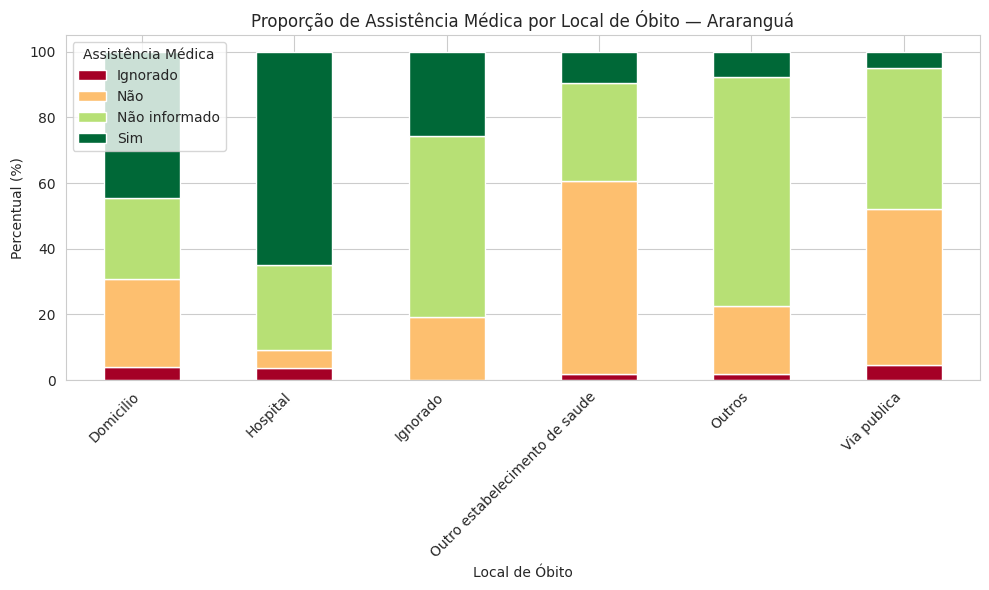

In [48]:
tabela_assist = pd.crosstab(
    df_limpo["LOCOCOR"],
    df_limpo["ASSISTMED_LABEL"],
    normalize="index"
) * 100

tabela_assist.plot(kind="bar", stacked=True, figsize=(10,6), colormap="RdYlGn")
plt.title("Proporção de Assistência Médica por Local de Óbito — Araranguá")
plt.ylabel("Percentual (%)")
plt.xlabel("Local de Óbito")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Assistência Médica")
plt.tight_layout()
plt.show()

## 4. Georreferenciamento das Ocorrências

Araranguá está na posição 47 de SC
Com 6909 óbitos registrados


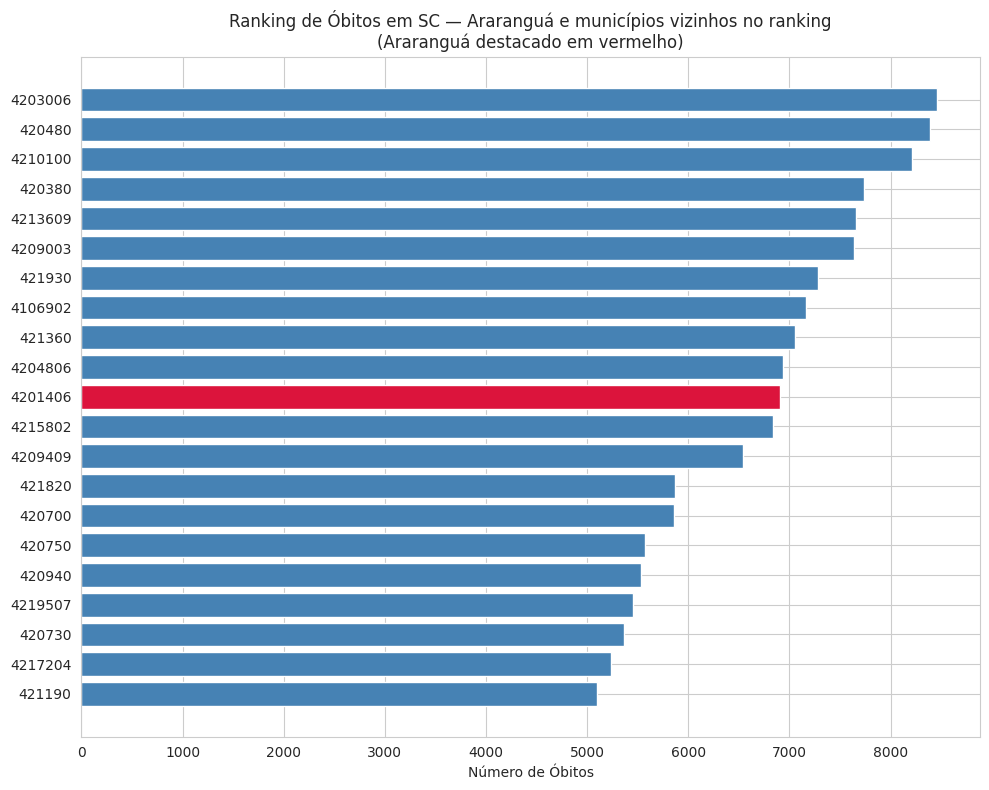

In [49]:
# Ranking de Araranguá em relação aos demais municípios de SC
contagem_municipios_sc = df["CODMUNOCOR"].value_counts().reset_index()
contagem_municipios_sc.columns = ["CODMUNOCOR", "obitos"]
contagem_municipios_sc = contagem_municipios_sc.reset_index(drop=False)
contagem_municipios_sc.columns = ["posicao", "CODMUNOCOR", "obitos"]

# Posição de Araranguá no ranking
pos_ararangua = contagem_municipios_sc[contagem_municipios_sc["CODMUNOCOR"] == CODIGO_ARARANGUA]
print(f"Araranguá está na posição {pos_ararangua['posicao'].values[0] + 1} de SC")
print(f"Com {pos_ararangua['obitos'].values[0]} óbitos registrados")

# Pega os 10 acima e 10 abaixo de Araranguá no ranking
idx = pos_ararangua.index[0]
vizinhos = contagem_municipios_sc.iloc[max(0, idx-10):idx+11].copy()

cores = ["crimson" if cod == CODIGO_ARARANGUA else "steelblue" for cod in vizinhos["CODMUNOCOR"]]

plt.figure(figsize=(10,8))
plt.barh(vizinhos["CODMUNOCOR"].astype(str), vizinhos["obitos"], color=cores)
plt.title("Ranking de Óbitos em SC — Araranguá e municípios vizinhos no ranking\n(Araranguá destacado em vermelho)")
plt.xlabel("Número de Óbitos")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [50]:
# Posição de Araranguá no ranking geral de SC
posicao = pos_ararangua['posicao'].values[0] + 1
total_municipios = len(contagem_municipios_sc)
obitos = pos_ararangua['obitos'].values[0]

print(f"Araranguá ocupa a {posicao}ª posição no ranking de óbitos de SC")
print(f"Total de municípios no dataset: {total_municipios}")
print(f"Número de óbitos registrados: {obitos}")
print(f"Araranguá está entre os {round(posicao/total_municipios*100, 1)}% municípios com mais óbitos em SC")

Araranguá ocupa a 47ª posição no ranking de óbitos de SC
Total de municípios no dataset: 2590
Número de óbitos registrados: 6909
Araranguá está entre os 1.8% municípios com mais óbitos em SC


## 5. Distribuição de Diagnósticos por Ambiente

In [51]:
top_causas_por_local = (
    df_limpo.groupby("LOCOCOR")["CAUSABAS"]
    .apply(lambda x: x.value_counts().head(5))
)
top_causas_por_local

LOCOCOR                             
Domicilio                       7999    133
                                410X    130
                                7989    111
                                R99      82
                                436X     77
Hospital                        I64     286
                                410X    238
                                I219    207
                                436X    134
                                J449    130
Ignorado                        V892      4
                                R99       4
                                W698      3
                                7999      3
                                C710      2
Outro estabelecimento de saude  8199    136
                                8147     16
                                8190     11
                                8191      7
                                8121      7
Outros                          W698     21
                                R99       4
                                W748      3
                                I219      2
                                R960      2
Via publica                     V892     53
                                9108     48
                                V445     13
                                V446      9
                                V099      9
Name: CAUSABAS, dtype: int64

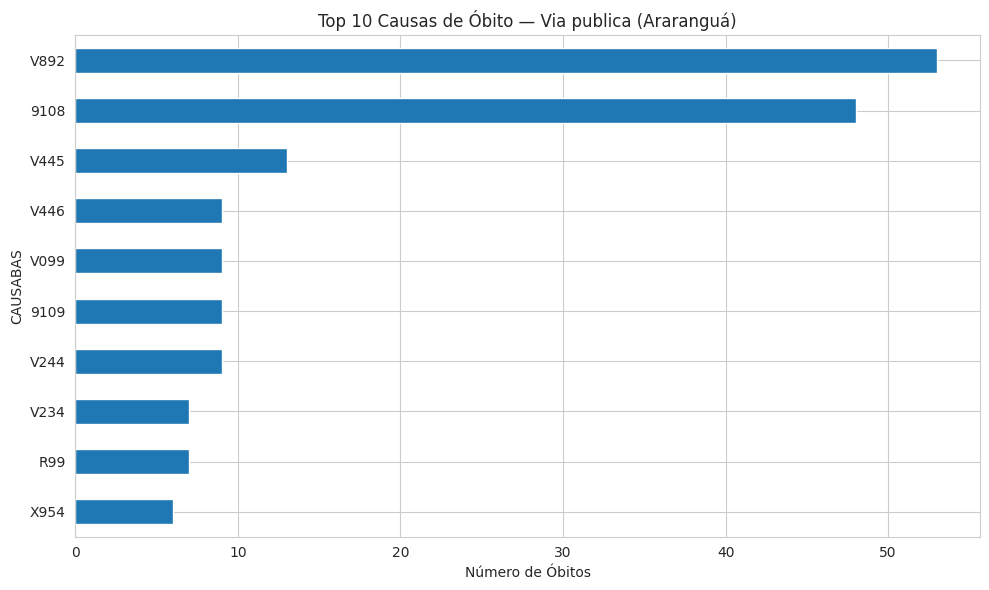

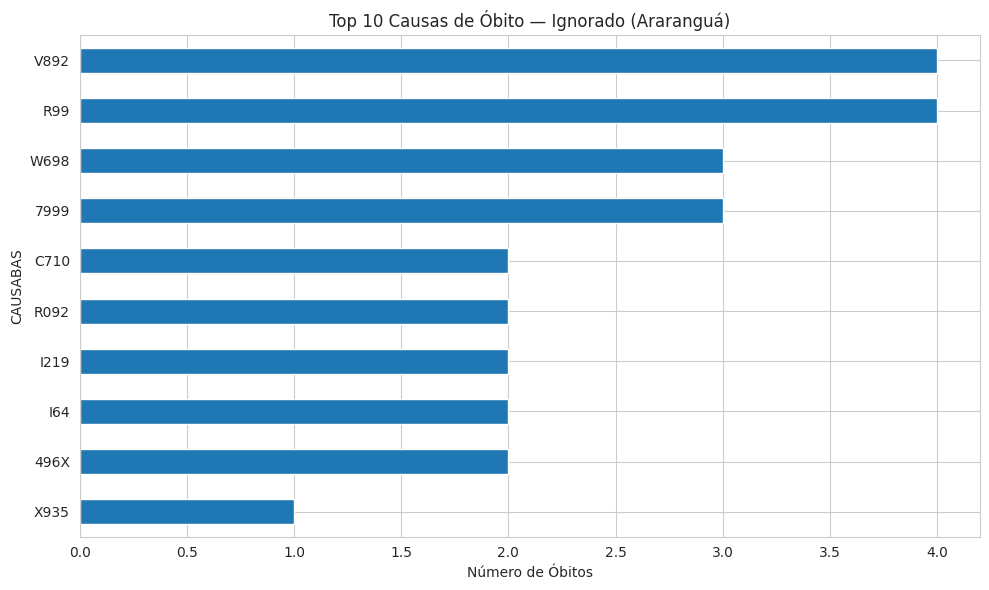

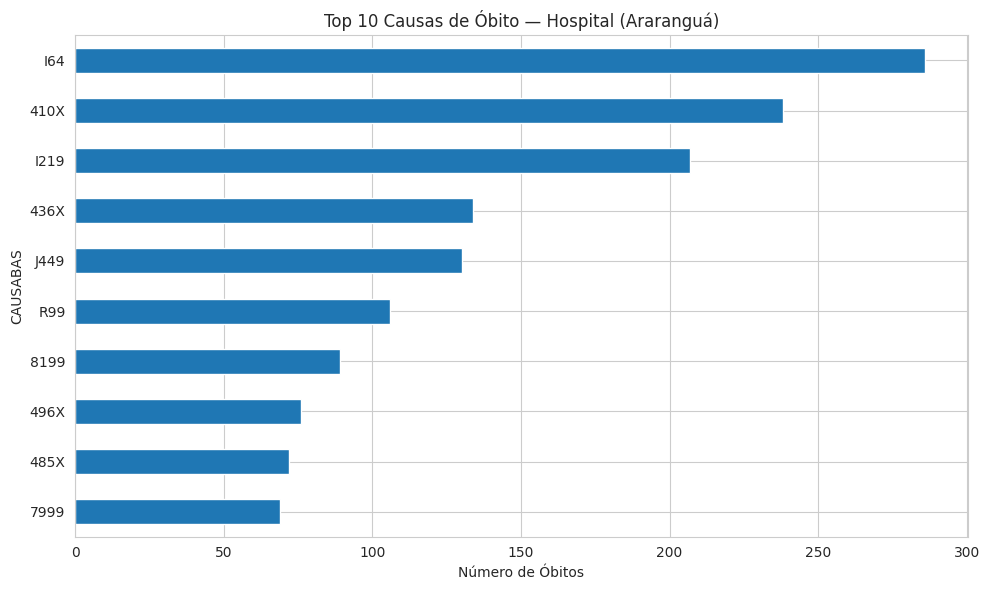

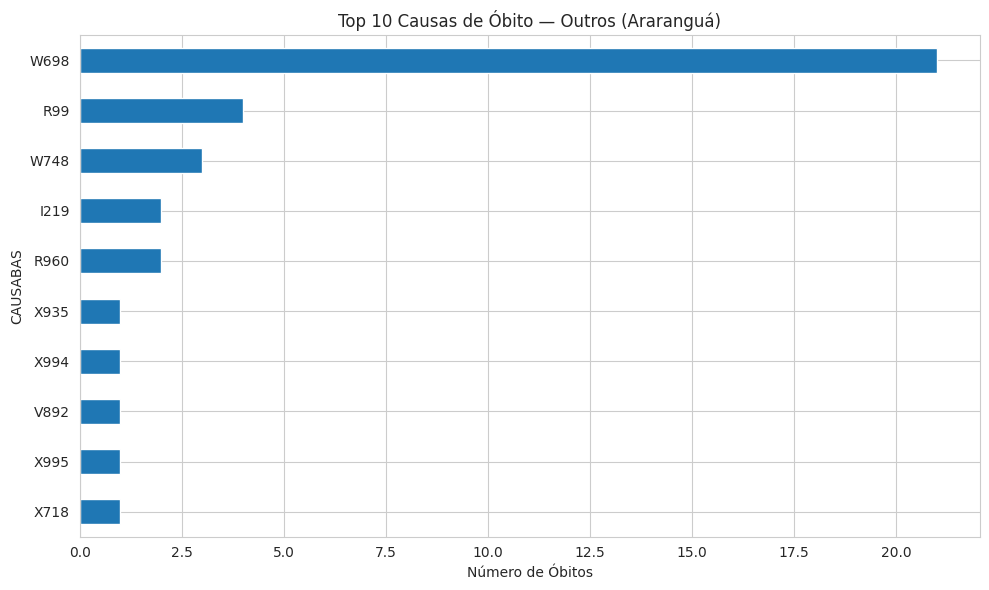

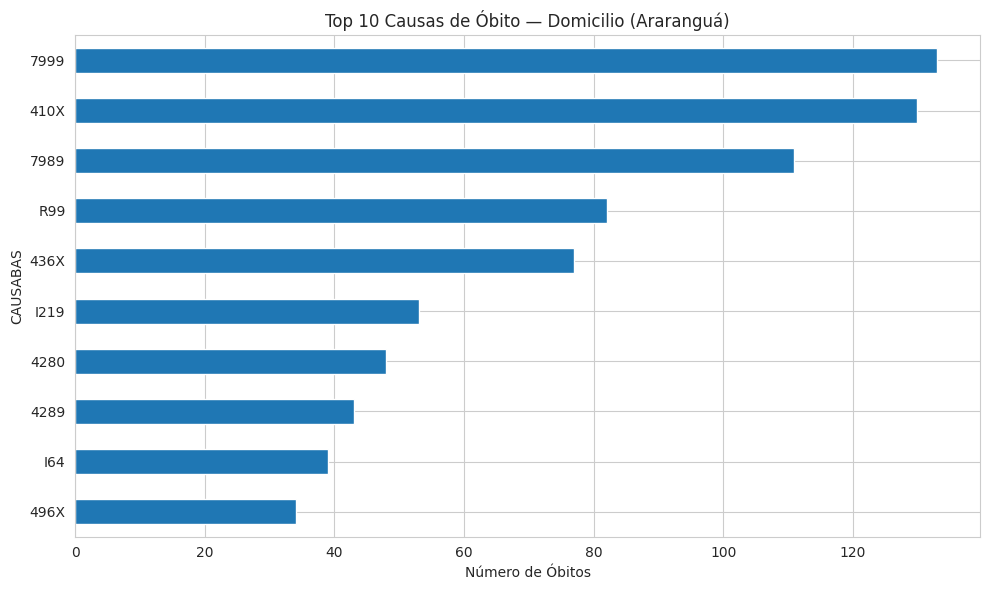

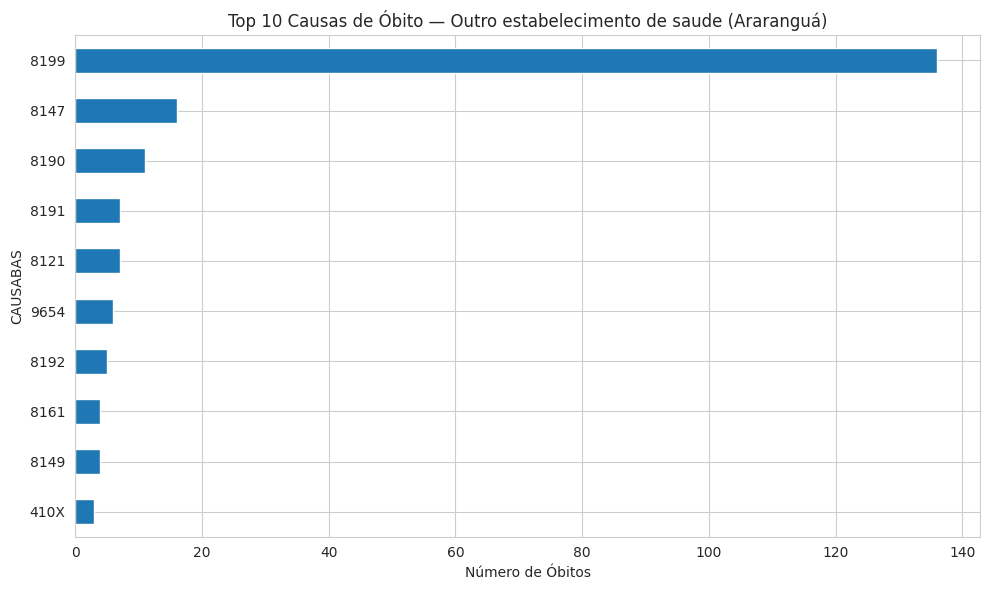

In [52]:
# Top 10 causas de óbito para cada local - um gráfico por local
locais = df_limpo["LOCOCOR"].unique()

for local in locais:
    causas_local = (
        df_limpo[df_limpo["LOCOCOR"] == local]["CAUSABAS"]
        .value_counts()
        .head(10)
    )

    if causas_local.empty:
        continue

    plt.figure(figsize=(10, 6))
    causas_local.plot(kind="barh")
    plt.title(f"Top 10 Causas de Óbito — {local} (Araranguá)")
    plt.xlabel("Número de Óbitos")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

## 6. Relatório Explicativo
